# 05 · Entrenamiento: DQN semi-Markov, líneas base, semillas e hiperparámetros

Notebook de demostración de la parte 05 (`code/train.py`). Guía: `docs/instrucciones/05_entrenamiento.md`. Lee los
artefactos que escribe `python main.py` (`baselines.csv`, `validation_results_fold_{k}.csv`, `run_metadata.json` y las
curvas); aquí no se entrena nada largo y **no se toca la prueba**.

**Objetivo de DQN con duración real.** Una transición dura τ horas de reloj (1 al esperar, de 1 a H o más al operar):

$$y = C + (1 - \text{terminado})\,\gamma^{\tau}\,\max_{x'} \bar Q(S', x'),\qquad \gamma \text{ por hora}.$$

`SemiMarkovReplayBuffer` guarda τ = `info["duration"]` y entrega $\gamma^\tau$ como el descuento por muestra que el `train`
de DQN de Stable-Baselines3 ya usa. La ruina (`terminated`) corta el bootstrap; el fin de la ventana (`truncated`) no.

In [1]:
import sys
sys.path.insert(0, "..")
sys.modules.pop("code", None)  # IPython ya importó el módulo `code` estándar (ver docs/decisiones.md)

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from gymnasium import spaces
from stable_baselines3.common.env_checker import check_env

from code import data, env, reward, train
from main import ARTIFACTS, BTC_CSV, FOLDS

ohlcv, _ = data.load_ohlcv(BTC_CSV)
features = data.compute_features(ohlcv)
fold_1 = data.build_fold_dataset(ohlcv, features, 1, FOLDS[1])
results = {k: pd.read_csv(ARTIFACTS / f"validation_results_fold_{k}.csv") for k in FOLDS}
metadata = json.loads((ARTIFACTS / "run_metadata.json").read_text())

## 1. El descuento es γ^τ

Tres transiciones a mano: una espera de 1 h, una operación de 24 h y una de 7 h (con hueco de datos). El buffer las
descuenta con $0.99^{1}$, $0.99^{24}$ y $0.99^{7}$; un DQN estándar las descontaría las tres con $0.99$.

In [2]:
obs_space, act_space = spaces.Box(-5, 5, shape=(2,), dtype=np.float32), spaces.Discrete(3)
buffer = train.SemiMarkovReplayBuffer(8, obs_space, act_space, device="cpu", gamma=0.99)
for i, tau in enumerate([1.0, 24.0, 7.0]):
    o = np.full((1, 2), i, dtype=np.float32)
    buffer.add(o, o + 1, np.array([[1]]), np.array([0.0]), np.array([False]), [{"duration": tau}])
samples = buffer._get_samples(np.array([0, 1, 2]))
pd.DataFrame({"τ (h)": [1, 24, 7], "descuento del buffer": samples.discounts.numpy().ravel(),
              "γ^τ": 0.99 ** np.array([1, 24, 7]), "DQN estándar (γ)": 0.99}).round(4)

,τ (h),descuento del buffer,γ^τ,DQN estándar (γ)
0,1,0.9900,0.9900,0.99
1,24,0.7857,0.7857,0.99
2,7,0.9321,0.9321,0.99


## 2. `check_env` antes de entrenar

El pipeline lo corre en el train de los cuatro folds con las advertencias convertidas en errores
(`run_training_stage`); aquí, el del fold 1.

In [3]:
with warnings.catch_warnings():
    warnings.simplefilter("error")
    check_env(env.make_env(fold_1, "train", reward.REWARDS[reward.DEFAULT_REWARD]), warn=True)
print("check_env: sin errores ni advertencias")

check_env: sin errores ni advertencias


## 3. Líneas base con costos

Aleatorio, siempre largo (24 h, con barreras) y siempre plano, en cada fold y partición (`artifacts/baselines.csv`).
`log_growth` = ln(capital final). Las triviales no tienen parámetros, así que recorrer su prueba no fija nada del agente.
Con costos de 0.125 % por lado, el aleatorio pierde en todas las particiones: el simulador no regala dinero.

In [4]:
baselines = pd.read_csv(ARTIFACTS / "baselines.csv")
baselines.pivot_table(index=["policy", "split"], columns="fold", values="log_growth").round(3)

fold                          1       2       3      4
policy        split                                   
aleatorio     test       -1.550  -1.616  -1.770 -0.120
              train      -8.330 -11.651 -10.076 -9.630
              validation -1.056  -1.312  -0.719 -1.833
siempre_largo test       -0.339  -1.047  -1.424 -0.484
              train      -5.114  -7.334  -7.678 -8.730
              validation -2.235  -0.339  -1.047 -1.424
siempre_plano test        0.000   0.000   0.000  0.000
              train       0.000   0.000   0.000  0.000
              validation  0.000   0.000   0.000  0.000

## 4. Búsqueda de hiperparámetros, solo en validación

Rejilla de 16 configuraciones (tasa de aprendizaje, γ por hora, red y fracción de exploración) × 3 semillas por fold,
cada corrida puntuada en validación en 6 puntos de control (50k a 300k pasos). **Criterio (A), fijado antes de ver
resultados:** el candidato (configuración, pasos) con mayor **mediana entre semillas** del crecimiento log en validación;
del candidato, la **semilla mediana**. Todas las filas están en `validation_results_fold_{k}.csv`.

In [5]:
pd.DataFrame(metadata["search_space"].items(), columns=["hiperparámetro", "valores"]).set_index("hiperparámetro")

,valores
hiperparámetro,
learning_rate,"[0.0001, 0.0005]"
gamma,"[0.99, 0.995]"
net_arch,"[[64, 64], [128, 128]]"
exploration_fraction,"[0.1, 0.3]"


In [6]:
rows = []
for k, r in results.items():
    medians = r.groupby(["config_id", "timesteps"])["val_log_growth"].median()
    c = metadata["chosen"][str(k)]
    rows.append({"fold": k, "candidatos": len(medians), "con mediana > 0": int((medians > 0).sum()),
                 "mediana de las medianas": medians.median(), "elegido: config": c["config_id"],
                 "pasos": c["timesteps"], "semilla": c["seed"], "mediana val": c["val_log_growth_median"],
                 "siempre plano val": 0.0})
pd.DataFrame(rows).set_index("fold").round(3)

,candidatos,con mediana > 0,mediana de las medianas,elegido: config,pasos,semilla,mediana val,siempre plano val
fold,,,,,,,,
1,96,2,-0.683,8,300000,0,0.225,0.0
2,96,0,-0.858,8,300000,1,-0.253,0.0
3,96,1,-0.591,8,250000,1,0.005,0.0
4,96,0,-0.693,8,300000,1,-0.063,0.0


**Dispersión entre semillas del candidato elegido** (crecimiento log en validación por semilla). Se reporta la
dispersión, no la mejor semilla: el modelo que va a prueba es el de la semilla mediana.

In [7]:
pd.DataFrame({k: c["val_log_growth_by_seed"] for k, c in metadata["chosen"].items()}).T.rename_axis("fold").round(3)

,0,1,2
fold,,,
1,0.225,0.609,-0.255
2,-0.125,-0.253,-0.485
3,0.037,0.005,-0.998
4,0.053,-0.063,-0.568


**Configuración elegida por fold** y estabilidad: si la misma configuración gana en folds con validaciones
distintas, la elección depende menos del azar de un año.

In [8]:
pd.DataFrame({k: {h: c[h] for h in ["config_id", "learning_rate", "gamma", "net_arch", "exploration_fraction",
                                     "timesteps", "seed"]} for k, c in metadata["chosen"].items()}).T

,config_id,learning_rate,gamma,net_arch,exploration_fraction,timesteps,seed
1,8,0.0005,0.99,"[64, 64]",0.1,300000,0
2,8,0.0005,0.99,"[64, 64]",0.1,300000,1
3,8,0.0005,0.99,"[64, 64]",0.1,250000,1
4,8,0.0005,0.99,"[64, 64]",0.1,300000,1


**Mediana entre candidatos por punto de control.** Más pasos no mejoran la validación de forma sistemática.

In [9]:
pd.DataFrame({k: r.groupby("timesteps")["val_log_growth"].median() for k, r in results.items()}).round(3)

,1,2,3,4
timesteps,,,,
50000,-0.745,-0.919,-0.680,-0.779
100000,-0.717,-0.884,-0.589,-0.868
150000,-0.715,-0.678,-0.671,-0.633
200000,-0.595,-0.846,-0.592,-0.721
250000,-0.402,-0.604,-0.627,-0.602
300000,-0.626,-0.801,-0.447,-0.680


## 5. Sobreajuste: train contra validación

El train solo se puntúa en el último punto de control (300k pasos), así que la comparación es en ese punto para ambos.
Cada punto es una corrida. En el train (recorrido completo, el mismo que vio al entrenar) el agente crece mucho; en
validación casi nunca le gana a no operar. Es la evidencia de que memoriza trayectorias del train y la razón para elegir
también los pasos en validación.

In [10]:
import matplotlib.pyplot as plt

last = {k: r[r["timesteps"] == r["timesteps"].max()] for k, r in results.items()}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, (k, r) in zip(axes, last.items()):
    ax.scatter(r["train_log_growth"], r["val_log_growth"], s=8, alpha=0.5)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"Fold {k} (último punto de control)")
    ax.set_xlabel("ln(capital) en train")
axes[0].set_ylabel("ln(capital) en validación")
fig.tight_layout()
pd.DataFrame({k: {"train (mediana)": r["train_log_growth"].median(), "validación (mediana)": r["val_log_growth"].median()}
              for k, r in last.items()}).round(3)

,1,2,3,4
train (mediana),21.539,22.164,19.700,17.38
validación (mediana),-0.626,-0.801,-0.447,-0.68


## 6. Curvas de entrenamiento (`training_curves_fold_{k}.png`)

Arriba, la recompensa por episodio de entrenamiento (ln del capital del episodio de 720 barras) de cada semilla de la
configuración elegida; abajo, su crecimiento log en validación en cada punto de control. La línea punteada marca el fin
de la exploración ε; la discontinua, el punto de control elegido.

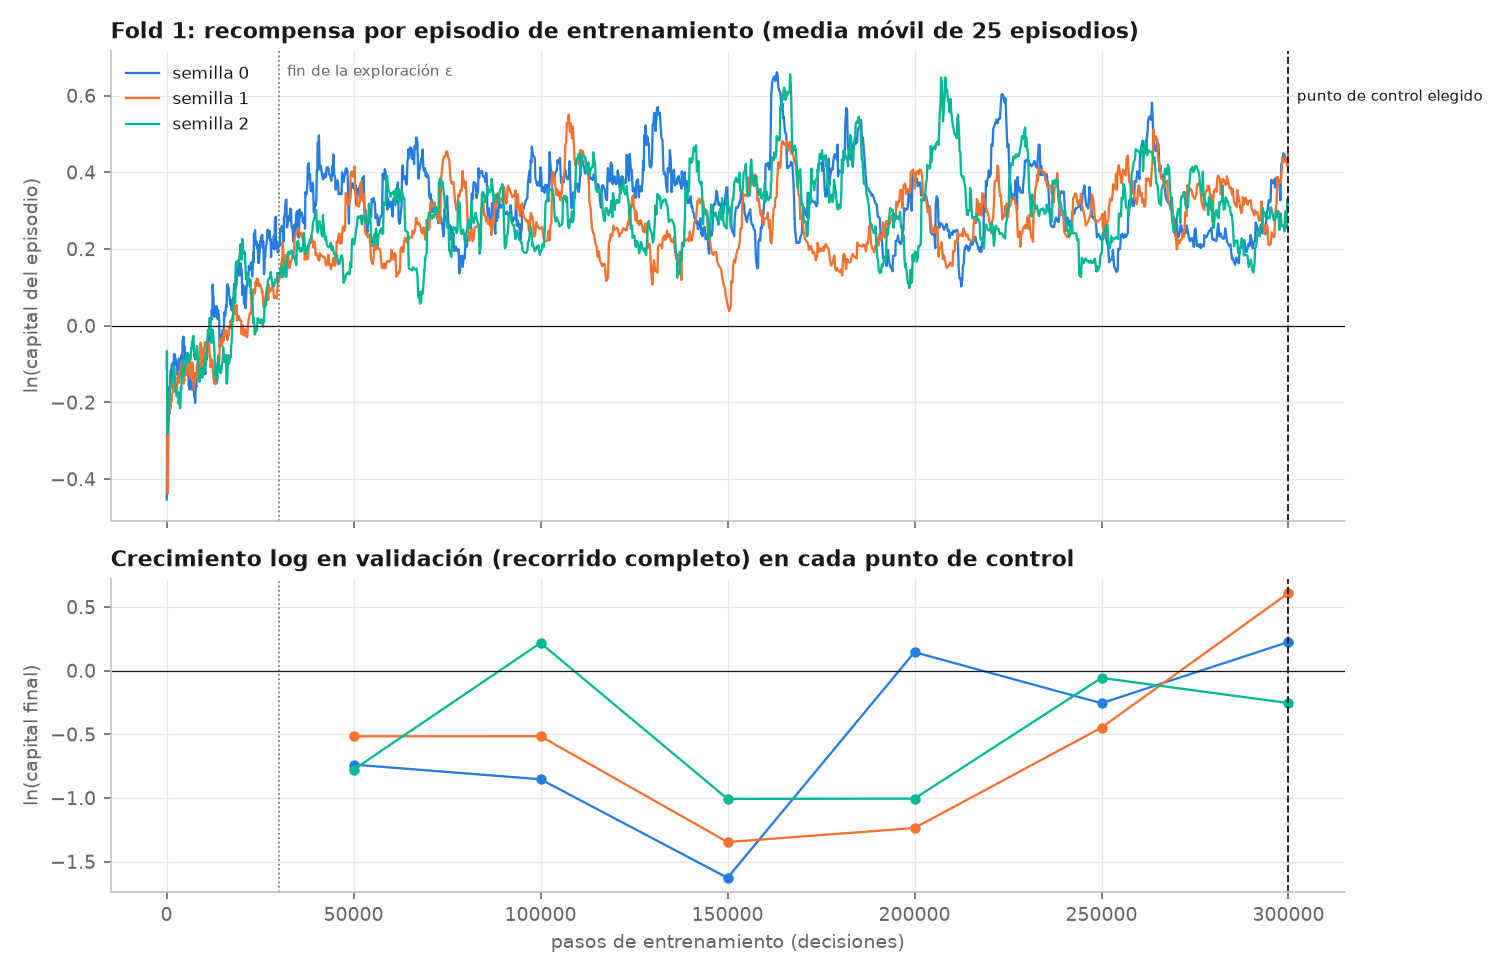

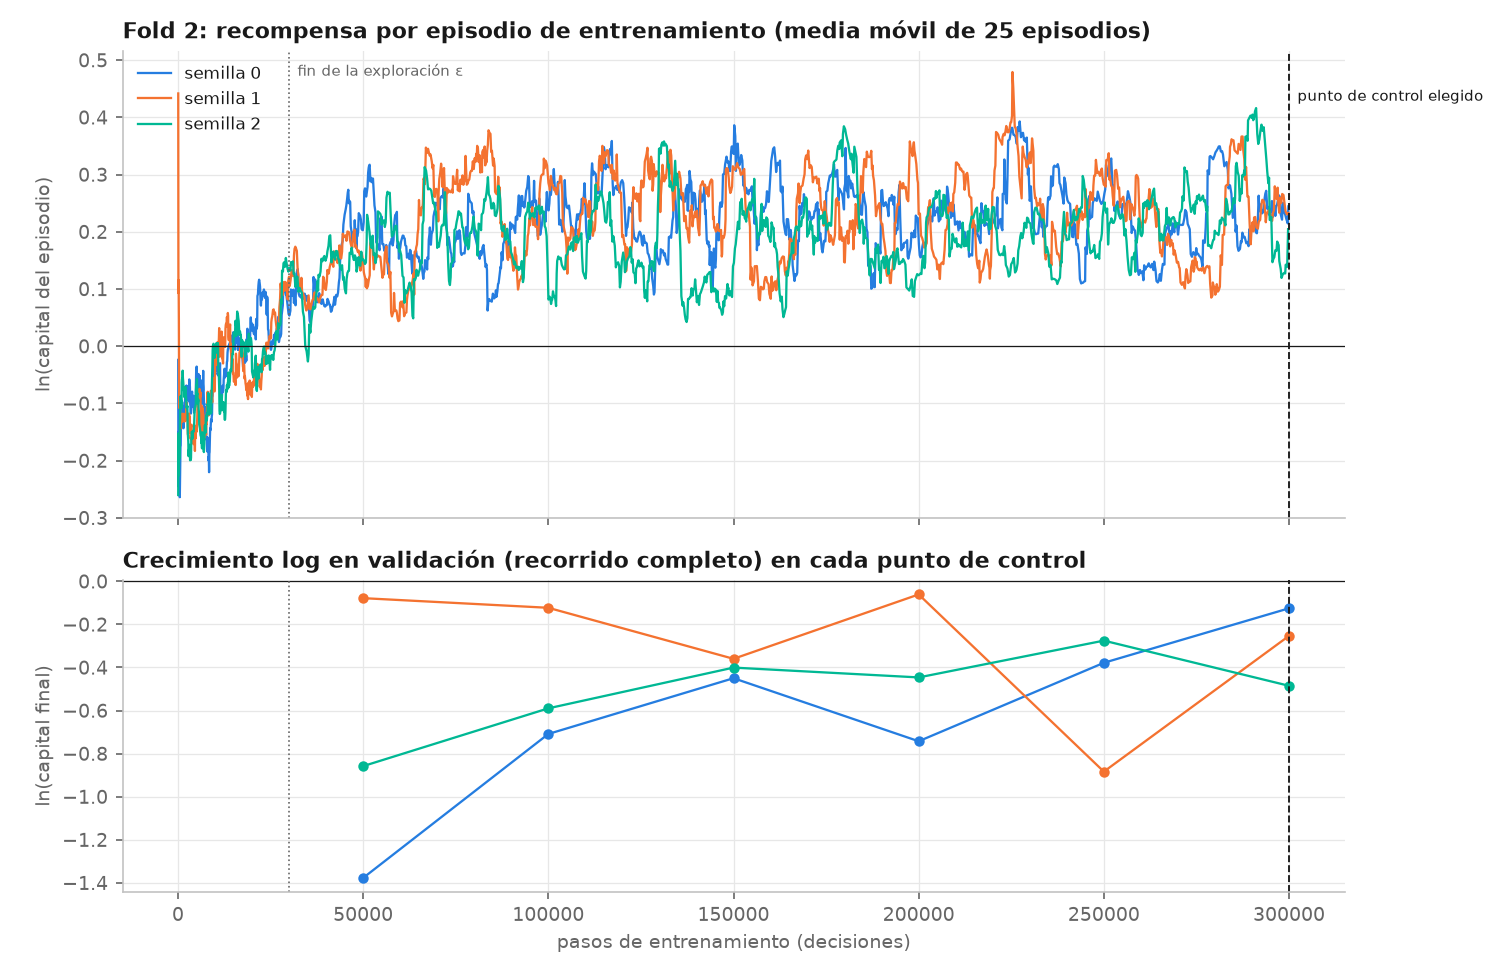

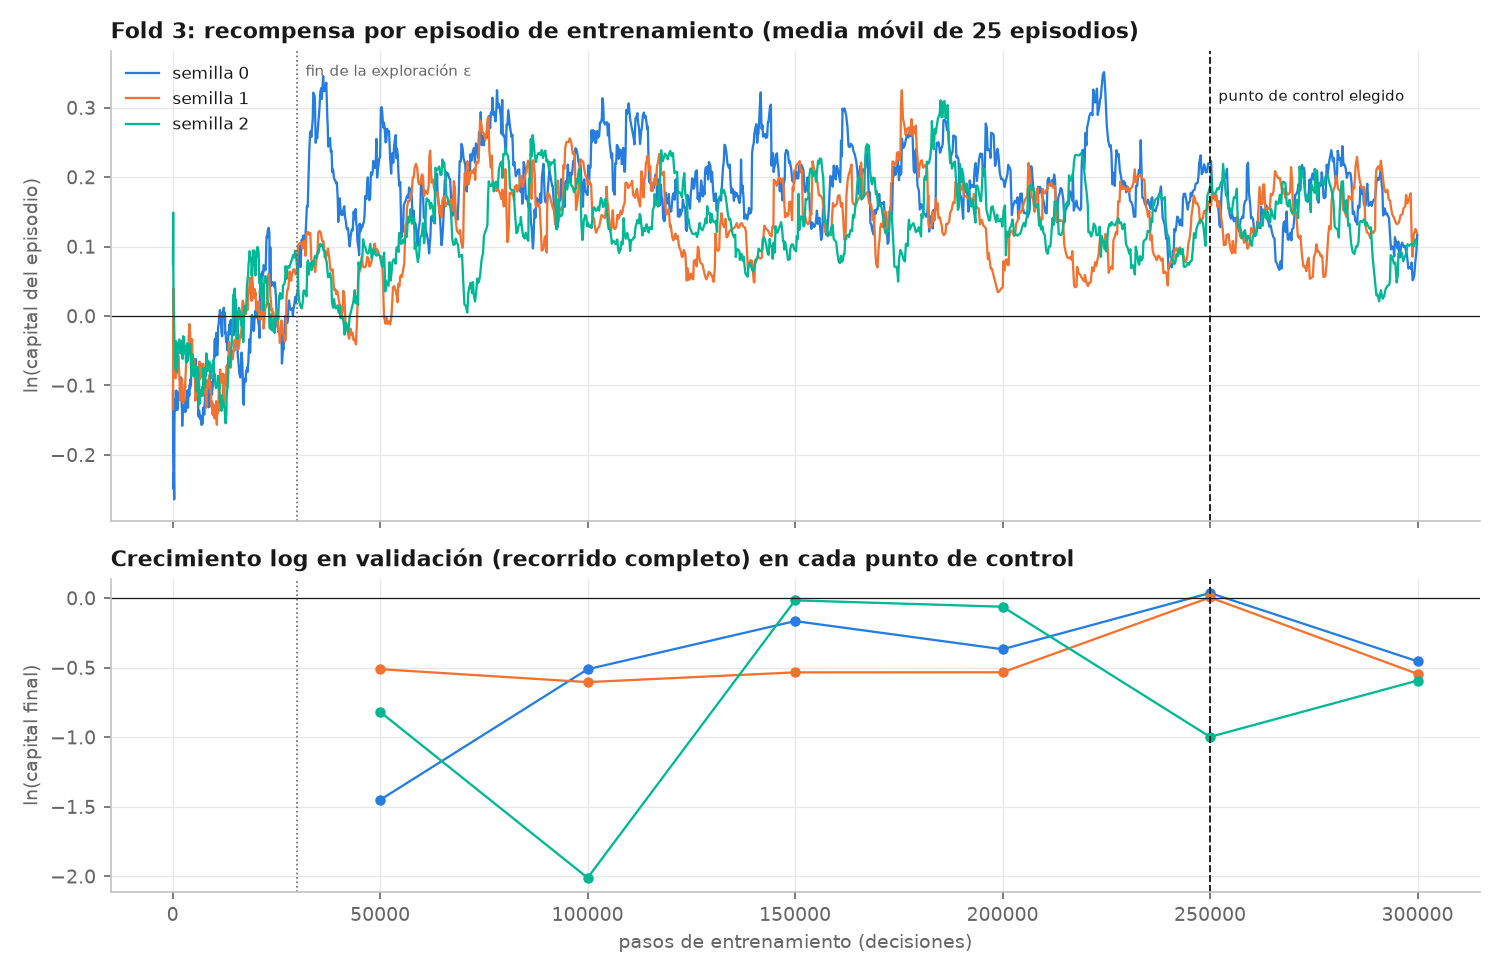

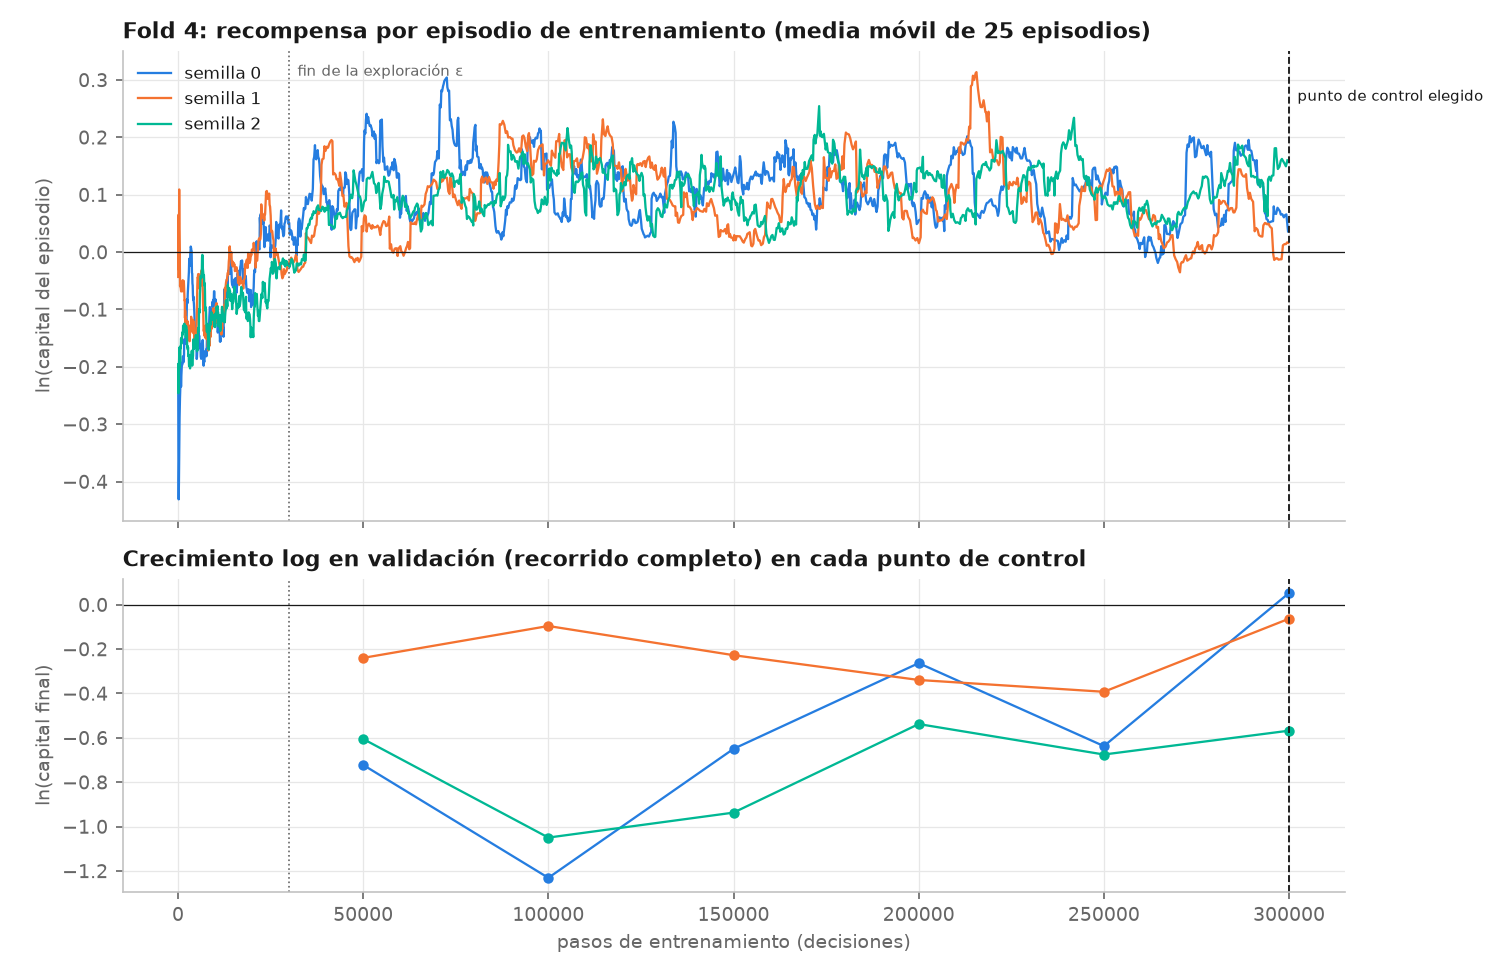

In [11]:
for k in FOLDS:
    display(Image(filename=str(ARTIFACTS / f"training_curves_fold_{k}.png"), width=850))

## 7. Metadatos de la corrida (`run_metadata.json`)

Versiones, semillas, configuración elegida por fold y tiempo de entrenamiento. Los modelos elegidos se congelan y
`run_training_stage` los devuelve como políticas `obs -> acción` para tocar la prueba **una sola vez** en la parte 06.

In [12]:
{k: metadata[k] for k in ["python", "stable_baselines3", "gymnasium", "torch", "seeds", "total_timesteps", "runs",
                           "processes", "training_minutes"]}

{'python': '3.12.2',
 'stable_baselines3': '2.9.2',
 'gymnasium': '1.4.0',
 'torch': '2.15.0',
 'seeds': [0, 1, 2],
 'total_timesteps': 300000,
 'runs': 192,
 'processes': 10,
 'training_minutes': 40.4}